# Polynomial coefficient recovery


## 1. Setup


In [7]:
from pathlib import Path
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from utilities.orponet import OrPoNet
from utilities.polynomial_basis import PolynomialFactory
from utilities.coeff_extractor import CoefficientExtractor
from utilities.training import Trainer


In [ ]:
SEED = 1234
DEVICE = torch.device("cpu")
DTYPE = torch.float64


## 2. Targets and reference coefficients


In [8]:
QUADRATURE_ORDER = 40

TRUE_TERMS = {
    (0, 0, 0): 1.0,
    (1, 0, 0): 0.8,
    (0, 2, 0): -0.6,
    (1, 1, 0): 0.5,
    (0, 0, 3): 0.35,
    (2, 0, 1): -0.25,
}  # (i, j, k) denotes P_i(x_1) P_j(x_2) P_k(x_3).


def polynomial_target(points):
    x, y, z = points[:, :1], points[:, 1:2], points[:, 2:3]
    p2_x, p2_y = (3 * x.square() - 1) / 2, (3 * y.square() - 1) / 2
    p3_z = (5 * z**3 - 3 * z) / 2
    return 1 + 0.8 * x - 0.6 * p2_y + 0.5 * x * y + 0.35 * p3_z - 0.25 * p2_x * z


def analytic_target(points):
    x, y, z = points[:, :1], points[:, 1:2], points[:, 2:3]
    return torch.exp(0.5 * x * y) + 0.7 * torch.sin(1.2 * z)


def projected_coefficients(target):
    nodes, weights = np.polynomial.legendre.leggauss(QUADRATURE_ORDER)
    nodes = torch.tensor(nodes, dtype=DTYPE, device=DEVICE)
    weights = torch.tensor(weights / 2, dtype=DTYPE, device=DEVICE)
    points = torch.cartesian_prod(nodes, nodes, nodes)
    values = target(points).reshape(
        QUADRATURE_ORDER, QUADRATURE_ORDER, QUADRATURE_ORDER
    )
    basis = PolynomialFactory.build_polynomial_values(
        {"type": "legendre", "degree": DEGREE},
        nodes[:, None],
        dtype=DTYPE,
    )
    # Uniform probability weights and the inverse Legendre norms (2n+1).
    weighted_basis = (
        weights[:, None] * basis * (2 * torch.arange(DEGREE + 1, device=DEVICE) + 1)
    )
    coefficients = torch.einsum(
        "abc,ai,bj,ck->ijk", values, weighted_basis, weighted_basis, weighted_basis
    )
    return coefficients.reshape(-1)


In [9]:
TRAIN_SAMPLES = 4096
VALIDATION_SAMPLES = 10000

generator = torch.Generator(device=DEVICE).manual_seed(SEED)

# data sampled within [0,1], we scale them to [-1,1]
train_x = (
    2 * torch.rand(TRAIN_SAMPLES, 3, generator=generator, dtype=DTYPE, device=DEVICE)
    - 1
)
# The analytic example's selection points follow its training draw in the original script.
analytic_validation_x = (
    2
    * torch.rand(VALIDATION_SAMPLES, 3, generator=generator, dtype=DTYPE, device=DEVICE)
    - 1
)
polynomial_validation_x = (
    2
    * torch.rand(
        VALIDATION_SAMPLES,
        3,
        generator=torch.Generator(device=DEVICE).manual_seed(SEED + 1),
        dtype=DTYPE,
        device=DEVICE,
    )
    - 1
)

examples = [
    {
        "name": "Polynomial",
        "target": polynomial_target,
        "validation_x": polynomial_validation_x,
        "l1_weight": 1e-5,
        "selection": None,
        "top_terms": 12,
    },
    {
        "name": "Analytic",
        "target": analytic_target,
        "validation_x": analytic_validation_x,
        "l1_weight": 1e-6,
        "selection": "validation_mse",
        "top_terms": 14,
    },
]


## 3. Training


In [10]:
DEGREE = 4
NEURON_COPIES = 4


def build_model():
    torch.manual_seed(SEED)
    model = OrPoNet(
        basis_configs=[
            {"type": "legendre", "degree": DEGREE, "constant_channels": 2}
            for _ in range(3)
        ],
        data_domain_lb=[-1] * 3,
        data_domain_ub=[1] * 3,
        training_domain_lb=[-1] * 3,
        training_domain_ub=[1] * 3,
        neuron_copies=NEURON_COPIES,
        normalize_basis=False,
        dtype=DTYPE,
    ).to(DEVICE)
    # Reset the random stream before the tutorial's basis-aware initialization.
    torch.manual_seed(SEED)

    model.apply_basis_aware_init(train_x, gain=0.1)
    return model


In [ ]:
RECORD_EVERY = 250

models = {}
histories = {}
for example in examples:
    print(f"Training {example['name']}", flush=True)
    model = build_model()
    train_y = example["target"](train_x)
    validation_x = example["validation_x"]
    validation_y = example["target"](validation_x)

    trainer = Trainer(
        model,
        (train_x, train_y),
        (validation_x, validation_y),
        selection=example["selection"],
    )

    train_loader = DataLoader(
        TensorDataset(train_x, train_y), batch_size=TRAIN_SAMPLES, shuffle=False
    )

    optimizer = torch.optim.AdamW(model.parameters(), lr=0.005, weight_decay=1e-6)

    trainer.fit(
        optimizer,
        epochs=3000,
        batches=train_loader,
        l1_weight=example["l1_weight"],
        record_every=RECORD_EVERY,
        log_every=RECORD_EVERY,
    )

    if example["selection"] is not None:
        trainer.restore_best()

    models[example["name"]] = model
    histories[example["name"]] = trainer.history


Training Polynomial


adamw 1: validation MSE=1.325e+00
adamw 250: validation MSE=2.951e-03
adamw 500: validation MSE=1.980e-04
adamw 750: validation MSE=7.011e-08
adamw 1000: validation MSE=5.075e-08
adamw 1250: validation MSE=5.867e-08
adamw 1500: validation MSE=5.165e-08
adamw 1750: validation MSE=5.173e-08
adamw 2000: validation MSE=1.142e-07
adamw 2250: validation MSE=9.653e-08
adamw 2500: validation MSE=4.486e-08
adamw 2750: validation MSE=7.100e-08
adamw 3000: validation MSE=6.478e-08
Training Analytic
adamw 1: validation MSE=1.243e+00
adamw 250: validation MSE=1.260e-05
adamw 500: validation MSE=1.530e-06
adamw 750: validation MSE=5.375e-07
adamw 1000: validation MSE=3.797e-07
adamw 1250: validation MSE=3.537e-07
adamw 1500: validation MSE=3.454e-07
adamw 1750: validation MSE=3.372e-07
adamw 2000: validation MSE=3.274e-07
adamw 2250: validation MSE=3.237e-07
adamw 2500: validation MSE=3.221e-07
adamw 2750: validation MSE=3.201e-07
adamw 3000: validation MSE=4.090e-07


## 4. Extract coefficients


In [ ]:
TEST_SAMPLES = 10000
ACTIVE_THRESHOLD = 0.001

test_generator = torch.Generator(device=DEVICE).manual_seed(SEED + 2)
test_x = (
    2
    * torch.rand(TEST_SAMPLES, 3, generator=test_generator, dtype=DTYPE, device=DEVICE)
    - 1
)
recovery = {}

for example in examples:
    name = example["name"]
    model = models[name]

    extractor = CoefficientExtractor(model)

    coefficients, indices = extractor.extract_coefficients()
    recovered = coefficients[:, 0]

    if name == "Polynomial":
        reference = recovered.new_tensor(
            [TRUE_TERMS.get(tuple(index), 0.0) for index in indices.tolist()]
        )
    else:
        reference = projected_coefficients(example["target"])

    # Keep all active reference terms, then fill with the largest other recovered terms.
    importance = torch.maximum(reference.abs(), recovered.abs())
    ranked = importance.argsort(descending=True).tolist()

    selected = [i for i in ranked if reference[i].abs() >= ACTIVE_THRESHOLD]

    selected += [i for i in ranked if i not in selected][
        : max(0, example["top_terms"] - len(selected))
    ]

    recovery[name] = {
        "reference": reference,
        "recovered": recovered,
        "indices": indices,
        "selected": selected,
    }


## 5. Coefficient comparison


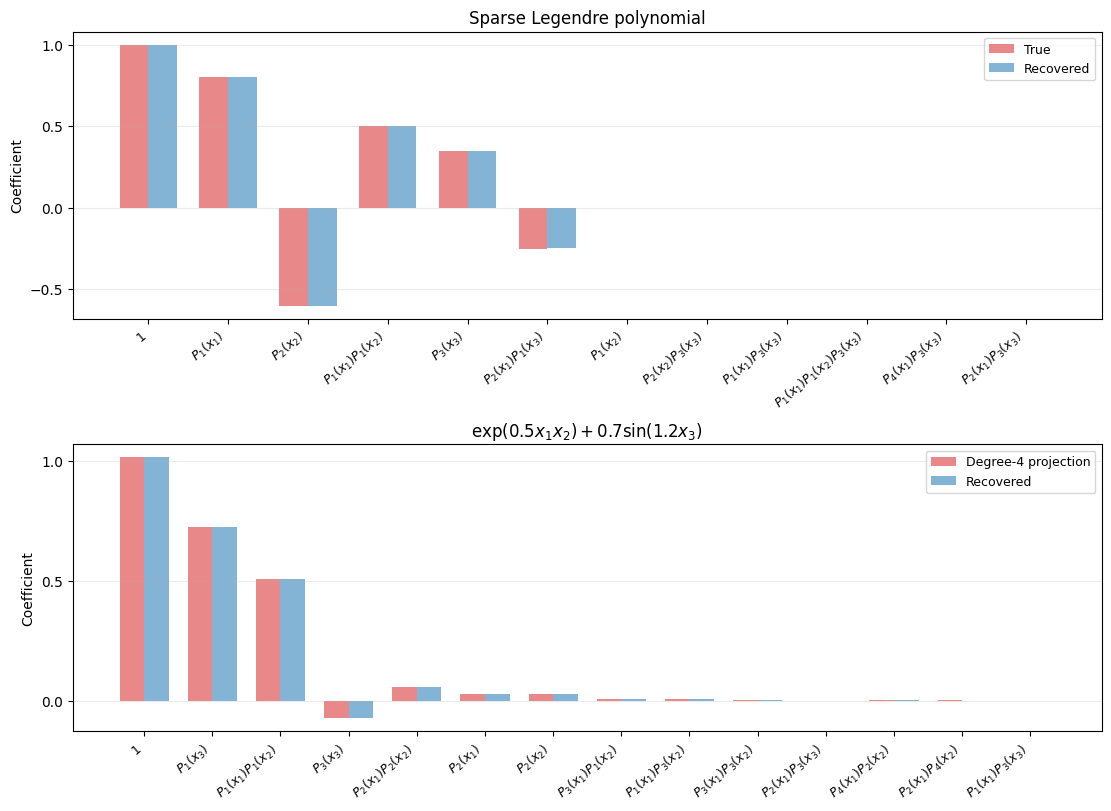

In [16]:
def term_label(index):
    factors = [
        rf"P_{{{degree}}}(x_{{{coordinate + 1}}})"
        for coordinate, degree in enumerate(index)
        if degree > 0
    ]
    return "$" + "".join(factors) + "$" if factors else "1"


fig, axes = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)
polynomial = recovery["Polynomial"]
selected = polynomial["selected"]
positions = np.arange(len(selected))

axes[0].bar(
    positions - 0.18,
    polynomial["reference"][selected].cpu(),
    width=0.36,
    label="True",
    color="#d62728",
    alpha=0.55,
)
axes[0].bar(
    positions + 0.18,
    polynomial["recovered"][selected].cpu(),
    width=0.36,
    label="Recovered",
    color="#1f77b4",
    alpha=0.55,
)

axes[0].set_xticks(
    positions,
    [term_label(index) for index in polynomial["indices"][selected].tolist()],
    rotation=40,
    ha="right",
    fontsize=9,
)
axes[0].set(title="Sparse Legendre polynomial", ylabel="Coefficient")
axes[0].set_yticks([-0.5, 0, 0.5, 1.0])
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(fontsize=9)
analytic = recovery["Analytic"]
selected = analytic["selected"]

positions = np.arange(len(selected))
axes[1].bar(
    positions - 0.18,
    analytic["reference"][selected].cpu(),
    width=0.36,
    label="Degree-4 projection",
    color="#d62728",
    alpha=0.55,
)
axes[1].bar(
    positions + 0.18,
    analytic["recovered"][selected].cpu(),
    width=0.36,
    label="Recovered",
    color="#1f77b4",
    alpha=0.55,
)

axes[1].set_xticks(
    positions,
    [term_label(index) for index in analytic["indices"][selected].tolist()],
    rotation=40,
    ha="right",
    fontsize=9,
)
axes[1].set(title=r"$\exp(0.5x_1x_2)+0.7\sin(1.2x_3)$", ylabel="Coefficient")
axes[1].set_yticks([0, 0.5, 1.0])
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(fontsize=9)
plt.show()
